## TUGAS 2 SBP LulusTepatWaktu.xlsx

In [14]:
# lib data manipulations
import numpy as np
import pandas as pd

# lib data visualizaton
import seaborn as sns
import matplotlib.pyplot as plt

# lib data preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# lib supervised learning
from sklearn.tree import DecisionTreeClassifier, plot_tree

# library evaluation model
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## LOAD DATASET

In [15]:
# read file
df = pd.read_excel("LulusTepatWaktu.xlsx")

# tampilkan 5 baris pertama
df.head()

,Lulus Tepat Waktu,Indeks Prestasi Kumulatif,Menulis Artikel Ilmiyah,Dosen Pembimbing,Menerima Beasiswa
0,Tidak,Baik,Tidak,Magister,Tidak
1,Ya,Baik,Tidak,Magister,Tidak
2,Tidak,Cumlaude,Ya,Magister,Ya
3,Tidak,Baik,Tidak,Doktor,Tidak
4,Tidak,Baik,Tidak,Doktor,Ya


In [16]:
# bacic info
df.info()

# rows and column
print("",df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 394 entries, 0 to 393
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Lulus Tepat Waktu          394 non-null    object
 1   Indeks Prestasi Kumulatif  394 non-null    object
 2   Menulis Artikel Ilmiyah    394 non-null    object
 3   Dosen Pembimbing           394 non-null    object
 4   Menerima Beasiswa          394 non-null    object
dtypes: object(5)
memory usage: 15.5+ KB
 (394, 5)


## SPLIT DATA

In [17]:
# copy data
df_encoded = df.copy()

#initialization label encoder
le = LabelEncoder()

# change string to number
for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        df_encoded[col] = le.fit_transform(df_encoded[col])

# checking encoding
print(df_encoded.head())

   Lulus Tepat Waktu  Indeks Prestasi Kumulatif  Menulis Artikel Ilmiyah  \
0                  0                          1                        0   
1                  1                          1                        0   
2                  0                          2                        1   
3                  0                          1                        0   
4                  0                          1                        0   

   Dosen Pembimbing  Menerima Beasiswa  
0                 2                  0  
1                 2                  0  
2                 2                  1  
3                 0                  0  
4                 0                  1  


In [18]:
# split fitures (x) and label (y)
x = df_encoded[["Indeks Prestasi Kumulatif", "Menulis Artikel Ilmiyah", "Dosen Pembimbing", "Menerima Beasiswa"]]
y = df_encoded["Lulus Tepat Waktu"]

In [19]:
# split validation
trainX, testX, trainY, testY = train_test_split(
  x, y, train_size=0.7, test_size=0.3, random_state=7, shuffle=True
)

In [20]:
# show dimension of data train
print(trainX.shape, trainY.shape)

(275, 4) (275,)


In [21]:
# show dimension of data test
print(testX.shape, testY.shape)

(119, 4) (119,)


## MODELING SUPERVISED LEARNING

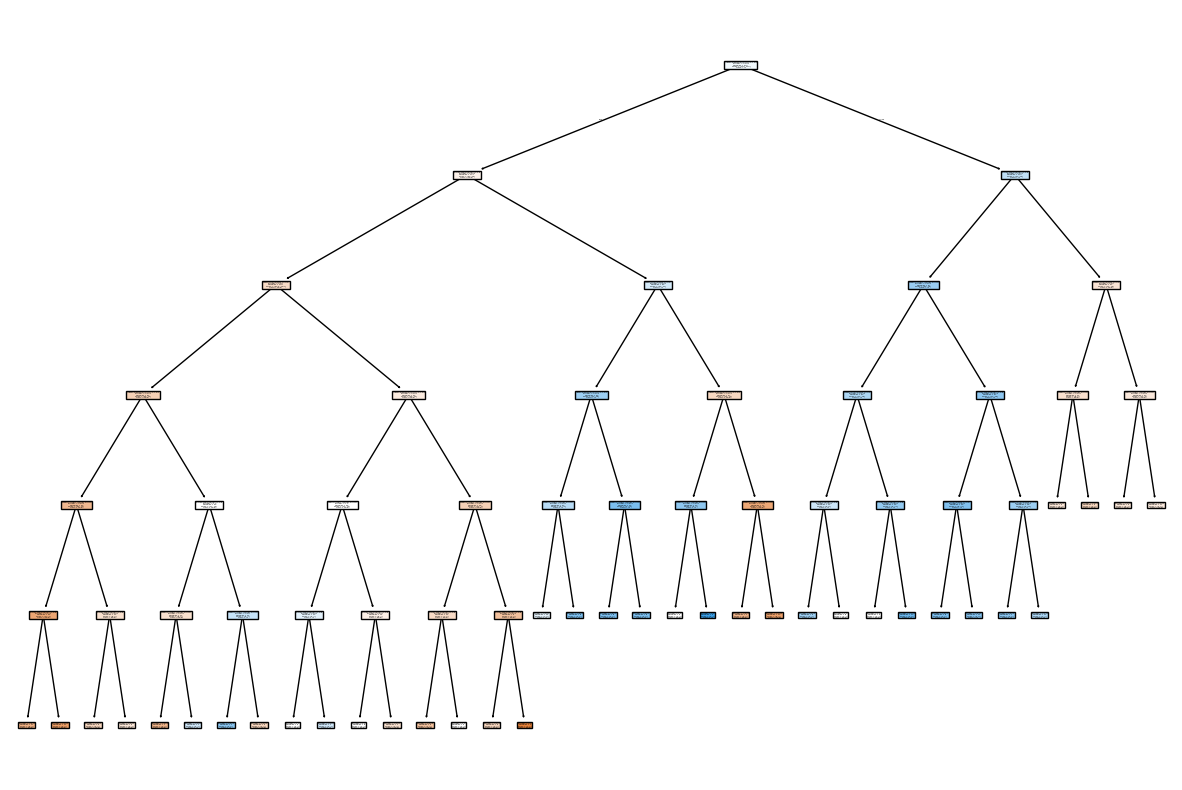

In [22]:
# supervised learning algorithm
model = DecisionTreeClassifier(criterion="entropy", random_state=42)
model.fit(trainX, trainY)

# show decision tree
plt.figure(figsize=(15, 10))
plot_tree(model, feature_names=x.columns, class_names=["Tidak", "Ya"], filled=True)
plt.show()

In [ ]:
# evaluation models - confusion_matrix
Ypred = model.predict(testX)

## SET CONFUSION MATRIX

In [24]:
# confusion matrix
cm = confusion_matrix(testY, Ypred)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[47 16]
 [41 15]]


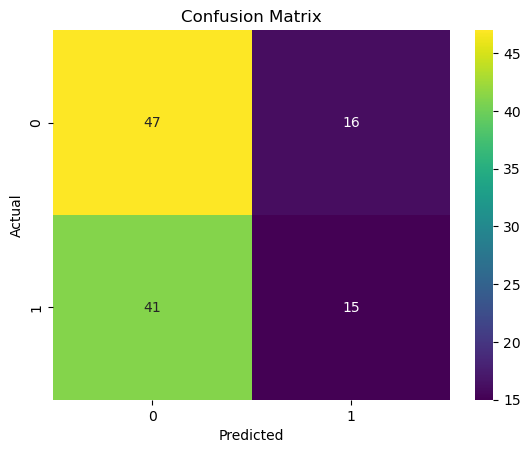

In [27]:
# visualization confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="viridis")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [28]:
# evaluation models - classification_report
print(classification_report(testY, Ypred))

# accuracy
acc = accuracy_score(testY, Ypred)
print("Accuracy:", acc)

              precision    recall  f1-score   support

           0       0.53      0.75      0.62        63
           1       0.48      0.27      0.34        56

    accuracy                           0.52       119
   macro avg       0.51      0.51      0.48       119
weighted avg       0.51      0.52      0.49       119

Accuracy: 0.5210084033613446
